# Lahore Weather 2020–2025: Exploratory Data Analysis

This notebook explores the clean data that the ETL pipeline (`python main.py`) saved into `lahore_weather.db`.

What we look at:
1. Summary statistics
2. Yearly temperature trends
3. Monthly and monsoon rainfall patterns
4. Season comparison
5. Correlation heatmap
6. Heatwave days

In [1]:
import sqlite3

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# A clean, simple look for all the charts
plt.rcParams.update({
    "figure.figsize": (9, 4.5),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.grid.axis": "y",
    "axes.axisbelow": True,
    "grid.color": "#e1e0d9",
    "font.size": 11,
})

BLUE = "#2a78d6"
LIGHT_BLUE = "#9ec5f4"
ORANGE = "#eb6834"

SEASON_ORDER = ["Winter", "Spring", "Summer", "Monsoon", "Autumn"]
WEATHER_COLUMNS = ["temp_max", "temp_min", "rainfall", "humidity", "wind_speed"]

## Load the data from SQLite

In [2]:
connection = sqlite3.connect("lahore_weather.db")
df = pd.read_sql("SELECT * FROM daily_weather", connection, parse_dates=["date"])

print(f"{len(df)} days, from {df['date'].min().date()} to {df['date'].max().date()}")
df.head()

2192 days, from 2020-01-01 to 2025-12-31


,date,temp_max,temp_min,rainfall,humidity,wind_speed,year,month,season
0,2020-01-01,13.5,2.0,0.0,90,10.1,2020,1,Winter
1,2020-01-02,18.0,3.9,0.0,85,10.4,2020,1,Winter
2,2020-01-03,18.1,4.2,0.0,77,9.6,2020,1,Winter
3,2020-01-04,16.4,5.3,0.2,80,10.2,2020,1,Winter
4,2020-01-05,16.0,5.0,1.0,82,8.6,2020,1,Winter


## 1. Summary statistics

In [3]:
df[WEATHER_COLUMNS].describe().round(1)

,temp_max,temp_min,rainfall,humidity,wind_speed
count,2192.0,2192.0,2192.0,2192.0,2192.0
mean,29.8,18.2,1.8,64.2,13.4
std,7.7,7.8,5.7,17.9,5.5
min,10.3,1.0,0.0,14.0,3.5
25%,23.6,11.3,0.0,54.0,9.5
50%,31.5,19.0,0.0,68.0,12.0
75%,35.4,25.4,0.4,78.0,16.3
max,46.5,33.2,93.9,96.0,43.4


**What we see**
- The average daily high is about 30°C, but it goes from 10°C on the coldest days up to 46.5°C at the peak of summer.
- Most days have no rain at all (the median is 0 mm). A few very wet days pull the average up to 1.8 mm.
- Humidity changes a lot, from very dry days (14%) to almost saturated air (96%).

## 2. Yearly temperature trends

Here we ask the database directly with SQL: the average daily high and low for each year.

In [4]:
yearly = pd.read_sql("""
    SELECT year,
           ROUND(AVG(temp_max), 1) AS avg_high,
           ROUND(AVG(temp_min), 1) AS avg_low
    FROM daily_weather
    GROUP BY year
""", connection)
yearly

,year,avg_high,avg_low
0,2020,29.6,17.8
1,2021,30.0,18.2
2,2022,30.4,18.4
3,2023,29.3,17.7
4,2024,29.5,17.9
5,2025,30.1,19.0


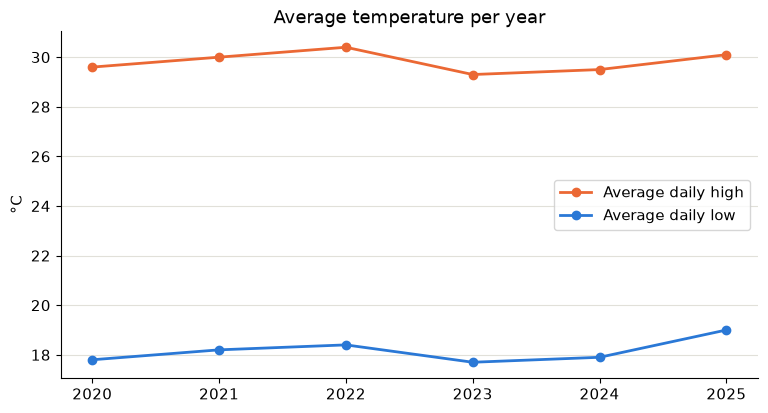

In [5]:
fig, ax = plt.subplots()
ax.plot(yearly["year"], yearly["avg_high"], marker="o", linewidth=2, color=ORANGE, label="Average daily high")
ax.plot(yearly["year"], yearly["avg_low"], marker="o", linewidth=2, color=BLUE, label="Average daily low")
ax.set_title("Average temperature per year")
ax.set_ylabel("°C")
ax.legend()
plt.show()

**What we see**
- Temperatures don't rise steadily every year; they go up and down.
- 2022 (30.4°C) and 2025 (30.1°C) had the hottest days on average. 2023 was the coolest year.
- 2025 had the warmest nights: an average low of 19.0°C, more than a degree above 2020 (17.8°C).

## 3. Rainfall patterns

### Average rainfall in each month

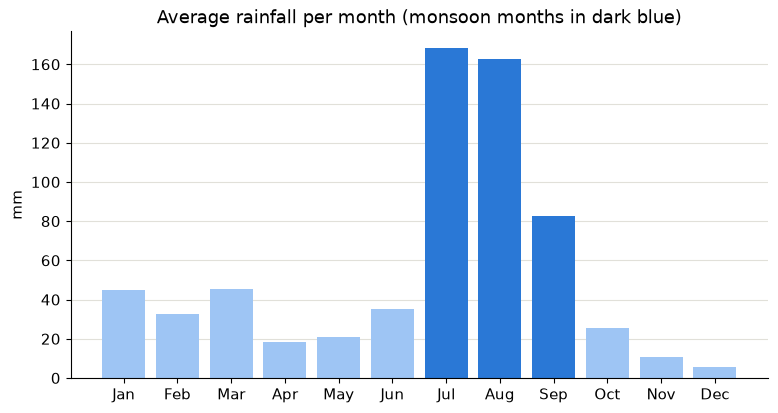

In [6]:
# Total rain in each month of each year, then the average of those totals per month
monthly_rain = df.groupby(["year", "month"])["rainfall"].sum().groupby("month").mean()

month_names = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
colors = [BLUE if month in (7, 8, 9) else LIGHT_BLUE for month in monthly_rain.index]

fig, ax = plt.subplots()
ax.bar(month_names, monthly_rain.values, color=colors)
ax.set_title("Average rainfall per month (monsoon months in dark blue)")
ax.set_ylabel("mm")
plt.show()

**What we see**
- July (168 mm) and August (163 mm) are by far the wettest months. With September, they make up the monsoon.
- November and December are the driest months, with barely any rain.

### Monsoon rainfall each year

In [7]:
yearly_rain = df.groupby("year")["rainfall"].sum()
monsoon_rain = df[df["season"] == "Monsoon"].groupby("year")["rainfall"].sum()

rain_table = pd.DataFrame({
    "total_rain_mm": yearly_rain.round(0),
    "monsoon_rain_mm": monsoon_rain.round(0),
    "monsoon_share_%": (monsoon_rain / yearly_rain * 100).round(0),
})
rain_table

,total_rain_mm,monsoon_rain_mm,monsoon_share_%
year,,,
2020,534.0,234.0,44.0
2021,352.0,208.0,59.0
2022,662.0,414.0,63.0
2023,782.0,452.0,58.0
2024,654.0,505.0,77.0
2025,932.0,669.0,72.0


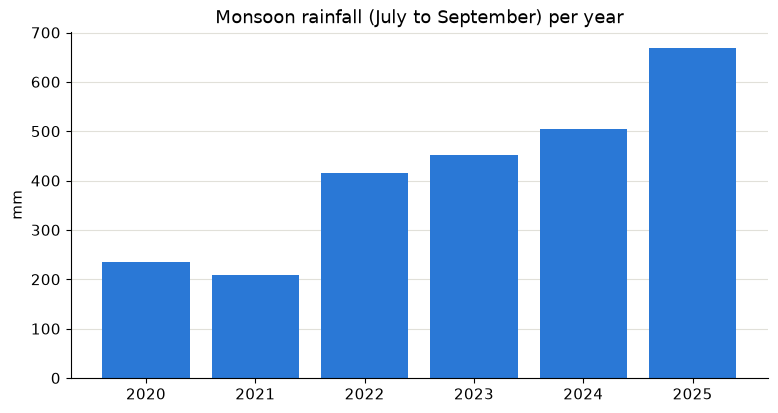

Wettest day: 2024-08-01 with 93.9 mm


In [8]:
fig, ax = plt.subplots()
ax.bar(monsoon_rain.index, monsoon_rain.values, color=BLUE)
ax.set_title("Monsoon rainfall (July to September) per year")
ax.set_ylabel("mm")
plt.show()

wettest = df.loc[df["rainfall"].idxmax()]
print(f"Wettest day: {wettest['date'].date()} with {wettest['rainfall']} mm")

**What we see**
- Monsoon rain grew a lot over these years: from 208 mm in 2021 to 669 mm in 2025, more than three times as much.
- In five of the six years the monsoon brought more than half of Lahore's yearly rain, peaking at 77% in 2024. 2020 was the exception (44%).
- The wettest single day was 1 August 2024, with 93.9 mm.

## 4. Season comparison

Average values per day in each season.

In [9]:
season_table = df.groupby("season")[WEATHER_COLUMNS].mean().round(1).loc[SEASON_ORDER]
season_table

,temp_max,temp_min,rainfall,humidity,wind_speed
season,,,,,
Winter,19.7,7.8,0.9,75.9,10.7
Spring,30.6,16.8,1.0,52.5,16.0
Summer,38.6,25.4,0.9,42.8,17.0
Monsoon,34.4,26.0,4.5,74.1,13.2
Autumn,28.5,15.9,0.6,65.3,11.3


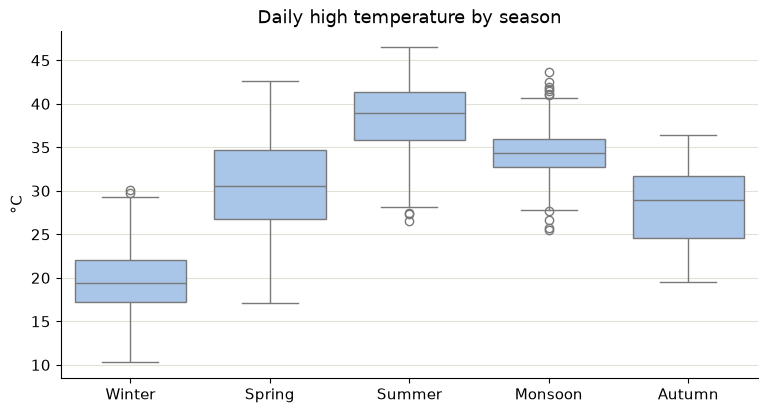

In [10]:
fig, ax = plt.subplots()
sns.boxplot(data=df, x="season", y="temp_max", order=SEASON_ORDER, color=LIGHT_BLUE, ax=ax)
ax.set_title("Daily high temperature by season")
ax.set_xlabel("")
ax.set_ylabel("°C")
plt.show()

**What we see**
- Summer (May–June) is the hottest season, with an average high of 38.6°C, and it also has the driest air (43% humidity).
- Monsoon days are a bit cooler (34.4°C) but its nights are the warmest (26.0°C) and the air is very humid (74%). That's why it feels so sticky.
- Winter is the coolest season (19.7°C high, 7.8°C low) and the most humid one (76%).
- Spring and Summer are the windiest seasons.

## 5. Correlation heatmap

How strongly the weather variables move together: +1 means they rise together, -1 means one rises as the other falls, 0 means no link.

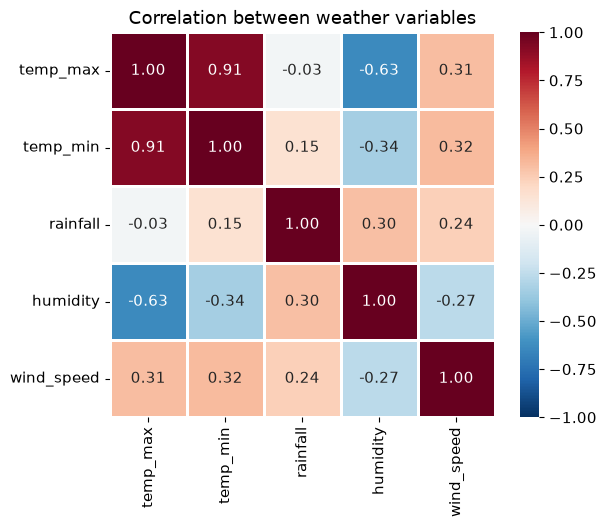

In [11]:
correlation = df[WEATHER_COLUMNS].corr()

fig, ax = plt.subplots(figsize=(6.5, 5))
sns.heatmap(correlation, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1,
            square=True, linewidths=2, linecolor="white", ax=ax)
ax.set_title("Correlation between weather variables")
plt.show()

**What we see**
- `temp_max` and `temp_min` are strongly linked (0.91): hot days usually come with warm nights.
- Humidity drops as the daytime temperature rises (-0.63): Lahore's hottest days are dry ones.
- Rainfall has only weak links with the other variables (the strongest is 0.30 with humidity), because most days have no rain at all.

## 6. Heatwave days

Our definitions:
- A **hot day** is a day with a high of **40°C or more**.
- A **heatwave day** is a hot day that is part of a run of **3 or more hot days in a row**.

In [12]:
df["hot_day"] = df["temp_max"] >= 40

# Every time hot_day switches between True and False a new "run" starts.
# We number the runs, then count how many days are in each one.
run_number = (df["hot_day"] != df["hot_day"].shift()).cumsum()
run_length = df.groupby(run_number)["hot_day"].transform("size")

df["heatwave_day"] = df["hot_day"] & (run_length >= 3)

heat_table = df.groupby("year")[["hot_day", "heatwave_day"]].sum()
heat_table

,hot_day,heatwave_day
year,,
2020,21,20
2021,23,21
2022,44,41
2023,8,4
2024,38,37
2025,32,23


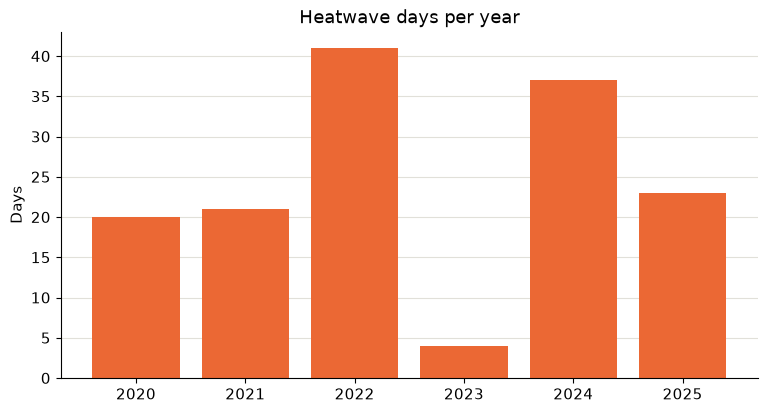

Hottest day: 2025-06-11 at 46.5°C


In [13]:
fig, ax = plt.subplots()
ax.bar(heat_table.index, heat_table["heatwave_day"], color=ORANGE)
ax.set_title("Heatwave days per year")
ax.set_ylabel("Days")
plt.show()

hottest = df.loc[df["temp_max"].idxmax()]
print(f"Hottest day: {hottest['date'].date()} at {hottest['temp_max']}°C")

**What we see**
- 2022 had the most heatwave days (41), followed by 2024 (37).
- 2023 was the mildest year, with only 4 heatwave days.
- Most hot days are part of a heatwave, so Lahore's heat comes in long spells rather than single days.
- The hottest day in the data was 11 June 2025, at 46.5°C.

In [14]:
connection.close()

## Key findings

- Lahore's year has a clear pattern: hot and dry in May–June, hot and humid in the July–September monsoon, cool and humid in winter.
- There is no steady warming from 2020 to 2025, but 2025 had the warmest nights, and 2022 and 2024 had the most heatwave days.
- Monsoon rainfall rose sharply, from 208 mm in 2021 to 669 mm in 2025, and in most years it brought more than half of the year's rain.
- The data is clean: 2,192 days, no missing values, and every day passed the Pydantic validation rules.